# Exploratory data analysis

**Question:** Which details about a reported crime are related to whether an arrest is recorded?

Run [the cleaning notebook](01_ingest_clean.ipynb) first. It explains the data sources, duplicate removal, missing values and arrest labels. Here, I use plots and group summaries to explore the cleaned records from 2010 through February 2024.

An arrest means a recorded adult or juvenile arrest (`AA` or `JA`). Other statuses mean **no arrest recorded in this copy of the data**, not that an arrest will never happen. The comparisons show patterns, not causes.


In [1]:
# load the libraries used for summaries and plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd


## Load and inspect the data


In [2]:
# load the cleaned data and check incident IDs and arrest labels
df = pd.read_parquet('../data/crime_clean.parquet').copy()
assert df['DR_NO'].is_unique, 'Run cleaning and resolve duplicate incidents'
assert df['Arrested'].isin([0, 1]).all(), 'Unexpected target values'
overall_arrest_rate = df['Arrested'].mean() * 100
print(f'Rows: {len(df):,}; columns: {len(df.columns)}')
df[['DATE OCC', 'Crm Cd Desc', 'AREA NAME', 'Arrested']].head(3)

Rows: 2,988,934; columns: 25


,DATE OCC,Crm Cd Desc,AREA NAME,Arrested
0,2010-02-20,VIOLATION OF COURT ORDER,Newton,1
1,2010-09-12,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",Pacific,0
2,2010-08-09,OTHER MISCELLANEOUS CRIME,Newton,0


In [3]:
# list the different crime codes and descriptions
codes = (df[['Crm Cd', 'Crm Cd Desc']].drop_duplicates()
         .sort_values('Crm Cd').reset_index(drop=True))
print(f'Distinct code-description pairs: {len(codes)}')
codes.head(10)

Distinct code-description pairs: 143


,Crm Cd,Crm Cd Desc
0,110,CRIMINAL HOMICIDE
1,113,"MANSLAUGHTER, NEGLIGENT"
2,121,"RAPE, FORCIBLE"
3,122,"RAPE, ATTEMPTED"
4,210,ROBBERY
5,220,ATTEMPTED ROBBERY
6,230,"ASSAULT WITH DEADLY WEAPON, AGGRAVATED ASSAULT"
7,231,ASSAULT WITH DEADLY WEAPON ON POLICE OFFICER
8,235,CHILD ABUSE (PHYSICAL) - AGGRAVATED ASSAULT
9,236,INTIMATE PARTNER - AGGRAVATED ASSAULT


In [4]:
# save the crime code list for reference
codes.to_csv('../data/crime_code_reference.csv', index=False)


## Group crimes into broader categories

I use fixed crime-code and description rules to create smaller, easier-to-read groups. The [LAPD reference](../docs/UCR-COMPSTAT062618.pdf) provides background. These are project groupings, not an official UCR classification. `Part II / Other` includes many different offenses, so its rate should not be treated as the rate for one crime type. Feature engineering uses the same rules.

In [5]:
# set up crime groups and words used to identify theft
ucr_part1_map = {
    110: 'Homicide', 113: 'Homicide',
    121: 'Rape', 122: 'Rape', 815: 'Rape', 820: 'Rape', 821: 'Rape',
    210: 'Robbery', 220: 'Robbery',
    230: 'Aggravated Assault', 231: 'Aggravated Assault',
    235: 'Aggravated Assault', 236: 'Aggravated Assault',
    250: 'Aggravated Assault', 251: 'Aggravated Assault',
    761: 'Aggravated Assault', 926: 'Aggravated Assault',
    310: 'Burglary', 320: 'Burglary',
    510: 'Motor Vehicle Theft', 520: 'Motor Vehicle Theft',
    522: 'Motor Vehicle Theft', 433: 'Motor Vehicle Theft',
    648: 'Arson',
    330: 'Larceny-Theft', 410: 'Larceny-Theft',
    480: 'Larceny-Theft', 485: 'Larceny-Theft', 487: 'Larceny-Theft'
}

larceny_keywords = [
    'THEFT', 'SHOPLIFT', 'PICKPOCKET', 'PURSE SNATCHING',
    'DRUNK ROLL', 'TILL TAP', 'EMBEZZLEMENT', 'BUNCO',
    'COIN MACHINE', 'IDENTITY'
]


In [6]:
# choose a crime group from its code and description
def map_ucr_part1(code, desc, part_1_2):
    try:
        code = int(code)
    except (TypeError, ValueError):
        if part_1_2 == 1:
            return 'Potential UCR Alignment'
        return 'Part II / Other'

    if code in ucr_part1_map:
        return ucr_part1_map[code]

    desc_upper = str(desc).upper()
    if any(keyword in desc_upper for keyword in larceny_keywords):
        return 'Larceny-Theft'
    if part_1_2 == 1:
        return 'Potential UCR Alignment'
    return 'Part II / Other'


In [7]:
# assign a crime group to each incident
df['Crime Group'] = df.apply(
    lambda row: map_ucr_part1(row['Crm Cd'], row['Crm Cd Desc'], row['Part 1-2']),
    axis=1)
df[['Crm Cd', 'Crm Cd Desc', 'Crime Group']].head(5)

,Crm Cd,Crm Cd Desc,Crime Group
0,900,VIOLATION OF COURT ORDER,Part II / Other
1,740,"VANDALISM - FELONY ($400 & OVER, ALL CHURCH VA...",Part II / Other
2,946,OTHER MISCELLANEOUS CRIME,Part II / Other
3,900,VIOLATION OF COURT ORDER,Part II / Other
4,122,"RAPE, ATTEMPTED",Rape


## Arrest rate summaries

The benchmark line is the overall arrest rate used for comparison across groups.


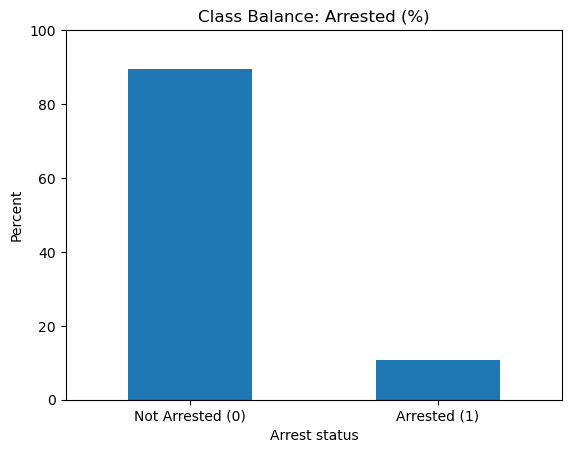

In [8]:
# plot the percentage of incidents with and without an arrest
class_pct = df['Arrested'].value_counts(normalize=True).sort_index() * 100

class_pct.plot(kind='bar')
plt.title('Class Balance: Arrested (%)')
plt.xlabel('Arrest status')
plt.ylabel('Percent')
plt.xticks([0, 1], ['Not Arrested (0)', 'Arrested (1)'], rotation=0)
plt.ylim(0, 100)
plt.savefig('../images/arrest_rate_class_balance.png', dpi=300, bbox_inches='tight')
plt.show()


In [9]:
# print the arrest percentages for the full dataset
print(f'Not Arrested (0): {class_pct.get(0, 0):.2f}%')
print(f'Arrested (1): {class_pct.get(1, 0):.2f}%')
overall_arrest_rate = df['Arrested'].mean() * 100
print(f'Overall arrest rate: {overall_arrest_rate:.2f}%')


Not Arrested (0): 89.39%
Arrested (1): 10.61%
Overall arrest rate: 10.61%


Most incidents do not have an arrest recorded. A model could therefore look accurate just by always predicting no arrest. Later, I will also use recall to show how many recorded arrests it finds and precision to show how often its arrest predictions are correct.

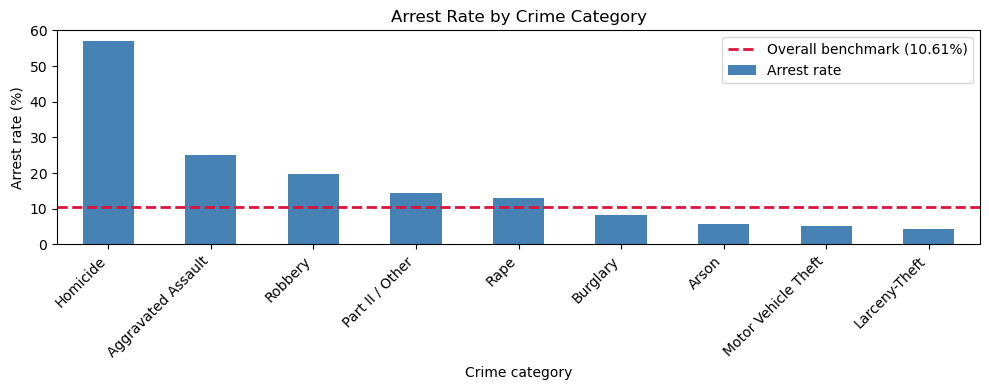

In [10]:
# compare arrest rates across crime groups
arrest_rate_by_cat = (df.groupby('Crime Group')['Arrested']
                      .mean()
                      .mul(100)
                      .sort_values(ascending=False))

ax = arrest_rate_by_cat.plot(kind='bar', figsize=(10, 4), color='steelblue', label='Arrest rate')
ax.axhline(overall_arrest_rate, color='crimson', linestyle='--', linewidth=2,
           label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
ax.set_title('Arrest Rate by Crime Category')
ax.set_xlabel('Crime category')
ax.set_ylabel('Arrest rate (%)')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_crime_category.png', dpi=300,
            bbox_inches='tight')
plt.show()


In [11]:
# calculate the arrest rate for each police area
area_rates = df.groupby('AREA NAME')[['Arrested']].mean()
area_rates = area_rates.rename(columns={'Arrested': 'arrest_rate'}).reset_index()
area_rates['arrest_rate_pct'] = area_rates['arrest_rate'] * 100
order_mode = 'sorted'

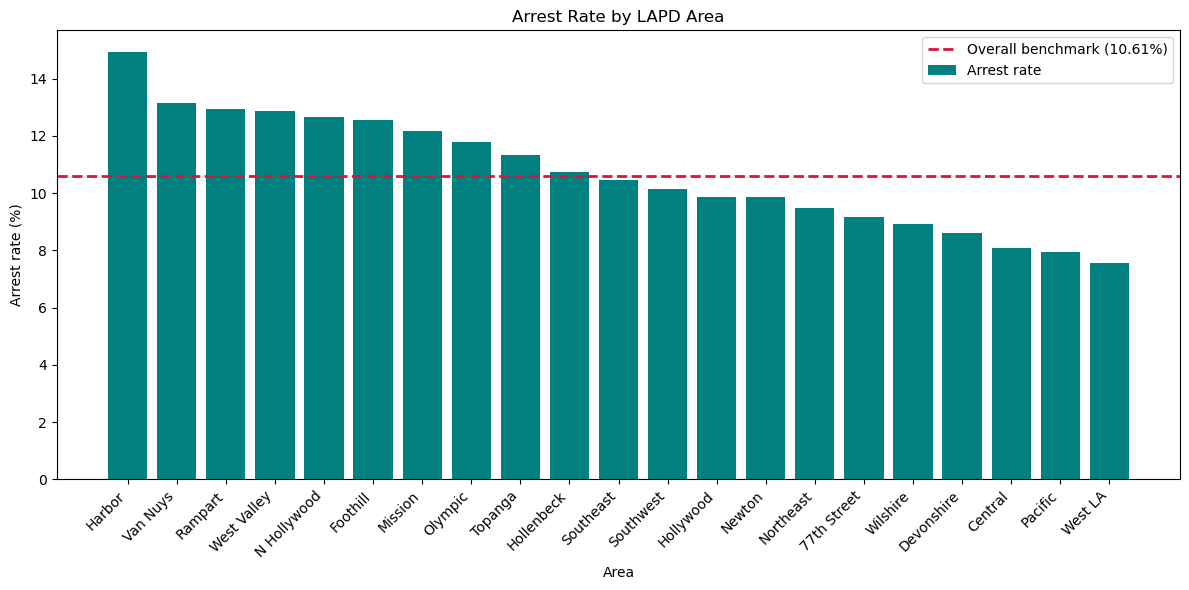

In [12]:
# plot police area rates against the overall arrest rate
if order_mode == 'sorted':
    area_plot = area_rates.sort_values(by='arrest_rate_pct', ascending=False)
else:
    area_plot = area_rates.sort_values(by='AREA NAME')

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(area_plot['AREA NAME'], area_plot['arrest_rate_pct'], color='teal', label='Arrest rate')
ax.axhline(overall_arrest_rate, color='crimson', linestyle='--', linewidth=2,
           label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
ax.set_title('Arrest Rate by LAPD Area')
ax.set_xlabel('Area')
ax.set_ylabel('Arrest rate (%)')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig(f'../images/arrest_rate_by_area_{order_mode}.png', dpi=300,
            bbox_inches='tight')
plt.show()


In [13]:
# show police area rates rounded to two decimal places
area_plot[['AREA NAME', 'arrest_rate_pct']].round(2)


,AREA NAME,arrest_rate_pct
4,Harbor,14.94
17,Van Nuys,13.16
13,Rampart,12.95
19,West Valley,12.88
8,N Hollywood,12.66
3,Foothill,12.55
7,Mission,12.19
11,Olympic,11.80
16,Topanga,11.33
5,Hollenbeck,10.73


In [14]:
# print the highest area and the range of area rates
print(f'Highest area rate: {area_rates.loc[area_rates["arrest_rate_pct"].idxmax(), "AREA NAME"]}')
print(f'Area rate range: {area_rates["arrest_rate_pct"].min():.2f}% to '
      f'{area_rates["arrest_rate_pct"].max():.2f}%')

Highest area rate: Harbor
Area rate range: 7.57% to 14.94%


### Does crime mix explain the area differences?

Areas see different mixes of crime, and some crimes are far more likely to end
in a recorded arrest. To separate the two, I compute the arrest rate each area
would have if its own crime mix were scored at citywide rates, then compare that
expected rate with the observed rate. The gap that remains is the part crime
mix does not explain. This is indirect standardization, not a causal estimate.

In [15]:
# compare observed area rates with what crime mix alone would predict
citywide_rate = df.groupby('Crime Group')['Arrested'].mean()
mix = pd.crosstab(df['AREA NAME'], df['Crime Group'], normalize='index')
expected_pct = mix.mul(citywide_rate, axis=1).sum(axis=1) * 100
observed_pct = df.groupby('AREA NAME')['Arrested'].mean() * 100
area_adjusted = pd.DataFrame({
    'observed_pct': observed_pct,
    'expected_pct': expected_pct
})
area_adjusted['gap_points'] = (
    area_adjusted['observed_pct'] - area_adjusted['expected_pct'])
area_adjusted = area_adjusted.sort_values(by='gap_points', ascending=False)
area_adjusted.round(2)

,observed_pct,expected_pct,gap_points
AREA NAME,,,
Harbor,14.94,10.86,4.08
Van Nuys,13.16,9.79,3.37
N Hollywood,12.66,9.69,2.97
West Valley,12.88,9.99,2.90
Foothill,12.55,10.53,2.02
Topanga,11.33,9.57,1.76
Mission,12.19,10.68,1.51
Rampart,12.95,11.65,1.29
Olympic,11.80,10.91,0.89


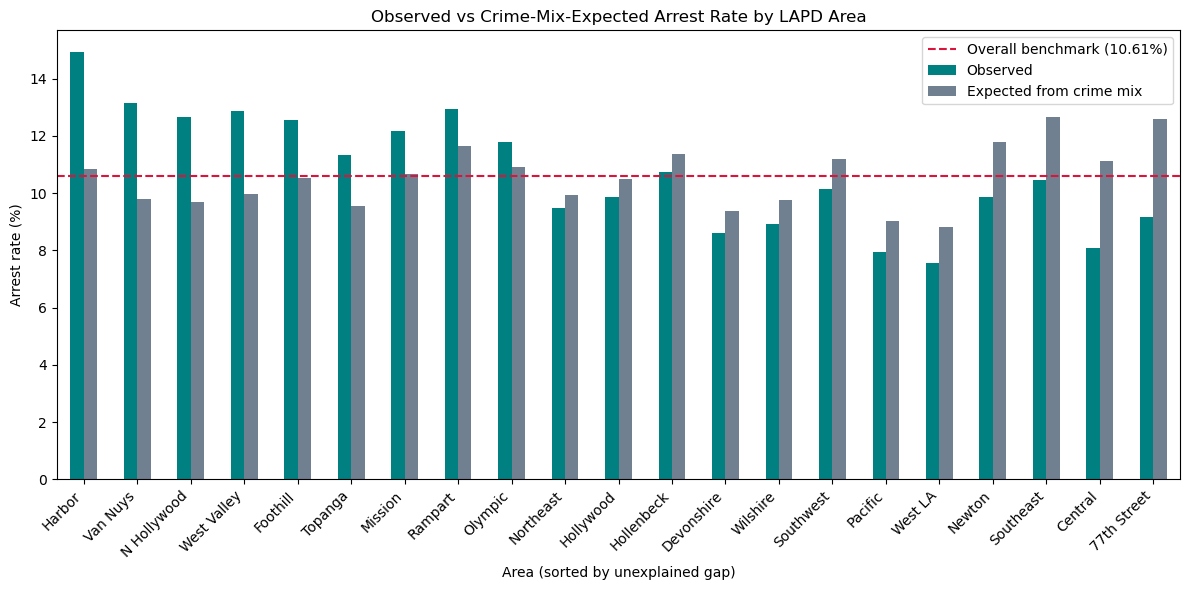

Largest unexplained gap: Harbor (+4.08 points)
Smallest: 77th Street (-3.44 points)


In [16]:
# plot observed against expected rates so the unexplained gap is visible
fig, ax = plt.subplots(figsize=(12, 6))
area_adjusted[['observed_pct', 'expected_pct']].rename(columns={
    'observed_pct': 'Observed',
    'expected_pct': 'Expected from crime mix'}).plot(
    kind='bar', ax=ax, color=['teal', 'slategray'])
ax.axhline(overall_arrest_rate, color='crimson', linestyle='--',
           label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
ax.set_title('Observed vs Crime-Mix-Expected Arrest Rate by LAPD Area')
ax.set_xlabel('Area (sorted by unexplained gap)')
ax.set_ylabel('Arrest rate (%)')
ax.legend()
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_area_adjusted.png', dpi=150)
plt.show()
print(f'Largest unexplained gap: {area_adjusted.index[0]} '
      f'({area_adjusted["gap_points"].iloc[0]:+.2f} points)')
print(f'Smallest: {area_adjusted.index[-1]} '
      f'({area_adjusted["gap_points"].iloc[-1]:+.2f} points)')

Crime mix explains very little of the area spread. The observed rates range over about 7.4 points and the unexplained gaps still range over about 7.5 points, from +4.1 for Harbor to -3.4 for 77th Street. What the adjustment does is reorder the areas: the divisions with the heaviest mix of violent crime (77th Street, Central, Southeast, Newton) would be expected to have the highest rates and instead come in two to three points below, while Harbor and the Valley divisions are expected to be near average and come in two to four points above. I would not read this as a measure of police performance; it could reflect case volume per officer, reporting practices, or how status is recorded. But it does mean the area differences are not an artifact of which crimes are reported where. Area and crime group both stay in the feature set.

### Mapping the area results

The bar charts hide geography. Here I join the area rates to the LAPD division boundaries published on the Los Angeles GeoHub and draw two maps: the observed arrest rate, and the unexplained gap after the crime-mix adjustment. Division names in the boundary file are upper case and two differ in spelling from the crime data, so I match them by hand.

In [17]:
# load the division boundaries and match their names to the crime data
lapd = gpd.read_file('../docs/lapd_divisions.geojson')
lapd['AREA NAME'] = lapd['APREC'].str.title().replace({
    'North Hollywood': 'N Hollywood', 'West Los Angeles': 'West LA',
    '77Th Street': '77th Street'})
lapd = lapd.merge(area_adjusted.reset_index(), on='AREA NAME', how='left')
missing_areas = lapd.loc[lapd['observed_pct'].isna(), 'APREC'].tolist()
print(f'Divisions in boundary file: {len(lapd)}')
print(f'Divisions without a matching crime-data area: {missing_areas}')

Divisions in boundary file: 21
Divisions without a matching crime-data area: []


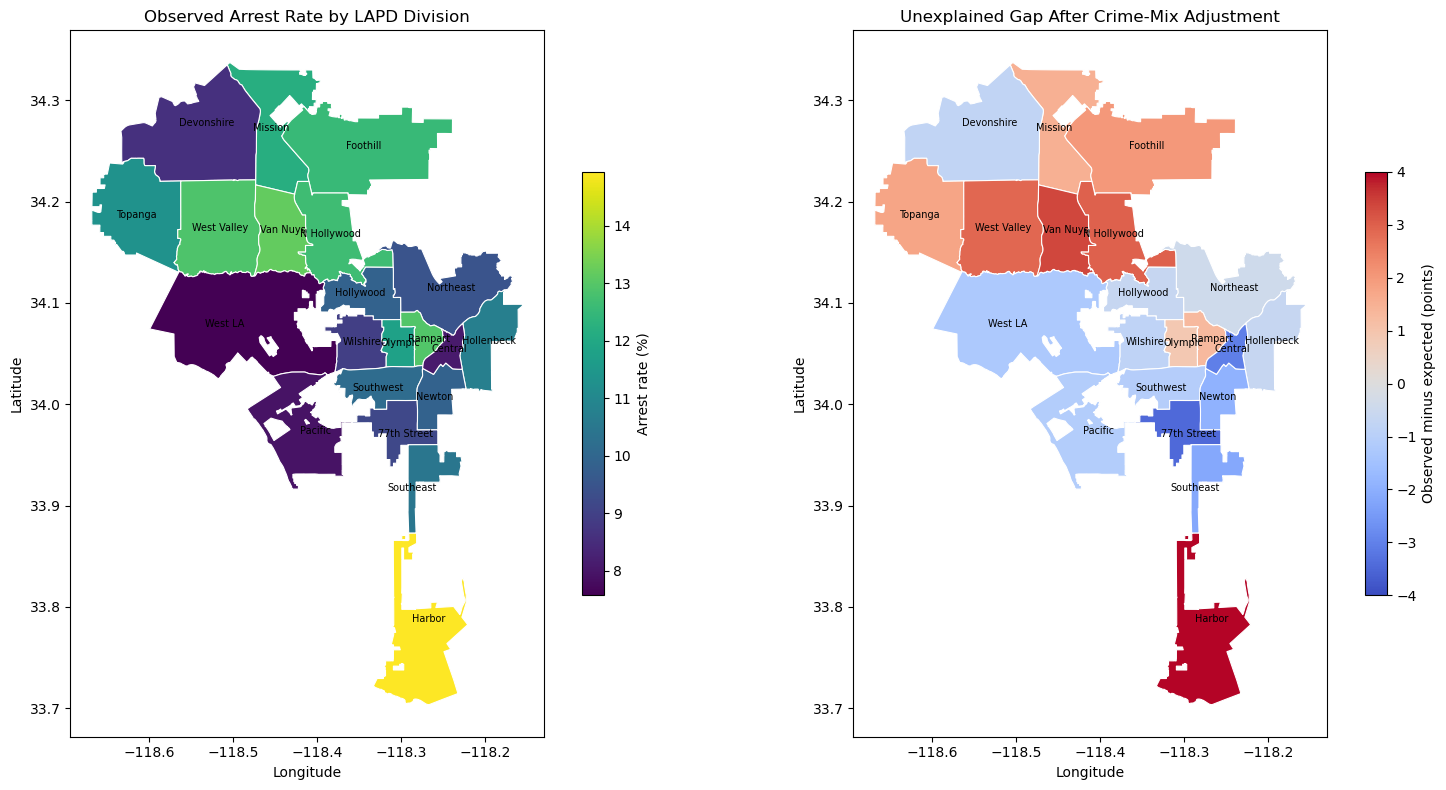

In [18]:
# map the observed arrest rate and the unexplained gap by division
fig, ax = plt.subplots(1, 2, figsize=(16, 8))
lapd.plot(column='observed_pct', cmap='viridis', edgecolor='white',
          linewidth=0.8, legend=True, ax=ax[0],
          legend_kwds={'label': 'Arrest rate (%)', 'shrink': 0.6})
ax[0].set_title('Observed Arrest Rate by LAPD Division')
lapd.plot(column='gap_points', cmap='coolwarm', vmin=-4, vmax=4,
          edgecolor='white', linewidth=0.8, legend=True, ax=ax[1],
          legend_kwds={'label': 'Observed minus expected (points)',
                       'shrink': 0.6})
ax[1].set_title('Unexplained Gap After Crime-Mix Adjustment')
for axis in ax:
    for _, row in lapd.iterrows():
        point = row['geometry'].representative_point()
        axis.annotate(row['AREA NAME'], (point.x, point.y),
                      fontsize=7, ha='center', va='center')
    axis.set_xlabel('Longitude')
    axis.set_ylabel('Latitude')
plt.tight_layout()
plt.savefig('../images/arrest_rate_map.png', dpi=150)
plt.show()

The map makes the pattern clearer than the table. The divisions that record more arrests than their crime mix predicts are the Valley divisions north of the hills and Harbor at the far south; those that record fewer are the Westside, the central basin and South Los Angeles. The split follows LAPD bureau boundaries more than it follows crime rates, which points toward something organizational, such as staffing, case volume per officer or how status is updated, rather than something about the crimes themselves. I cannot test that with these records.

In [19]:
# get the year, month and hour of each incident
tmp = df.copy()
tmp['year'] = pd.to_datetime(tmp['DATE OCC']).dt.year
tmp['month'] = pd.to_datetime(tmp['DATE OCC']).dt.month
tmp['hour'] = tmp['TIME OCC'].astype(str).str.zfill(4).str[:2].astype(int)


In [20]:
# calculate arrest rates by year, month and hour
year_rate = tmp.groupby('year')['Arrested'].mean().mul(100)
month_rate = tmp.groupby('month')['Arrested'].mean().mul(100).reindex(range(1, 13))
hour_rate = tmp.groupby('hour')['Arrested'].mean().mul(100).reindex(range(24))


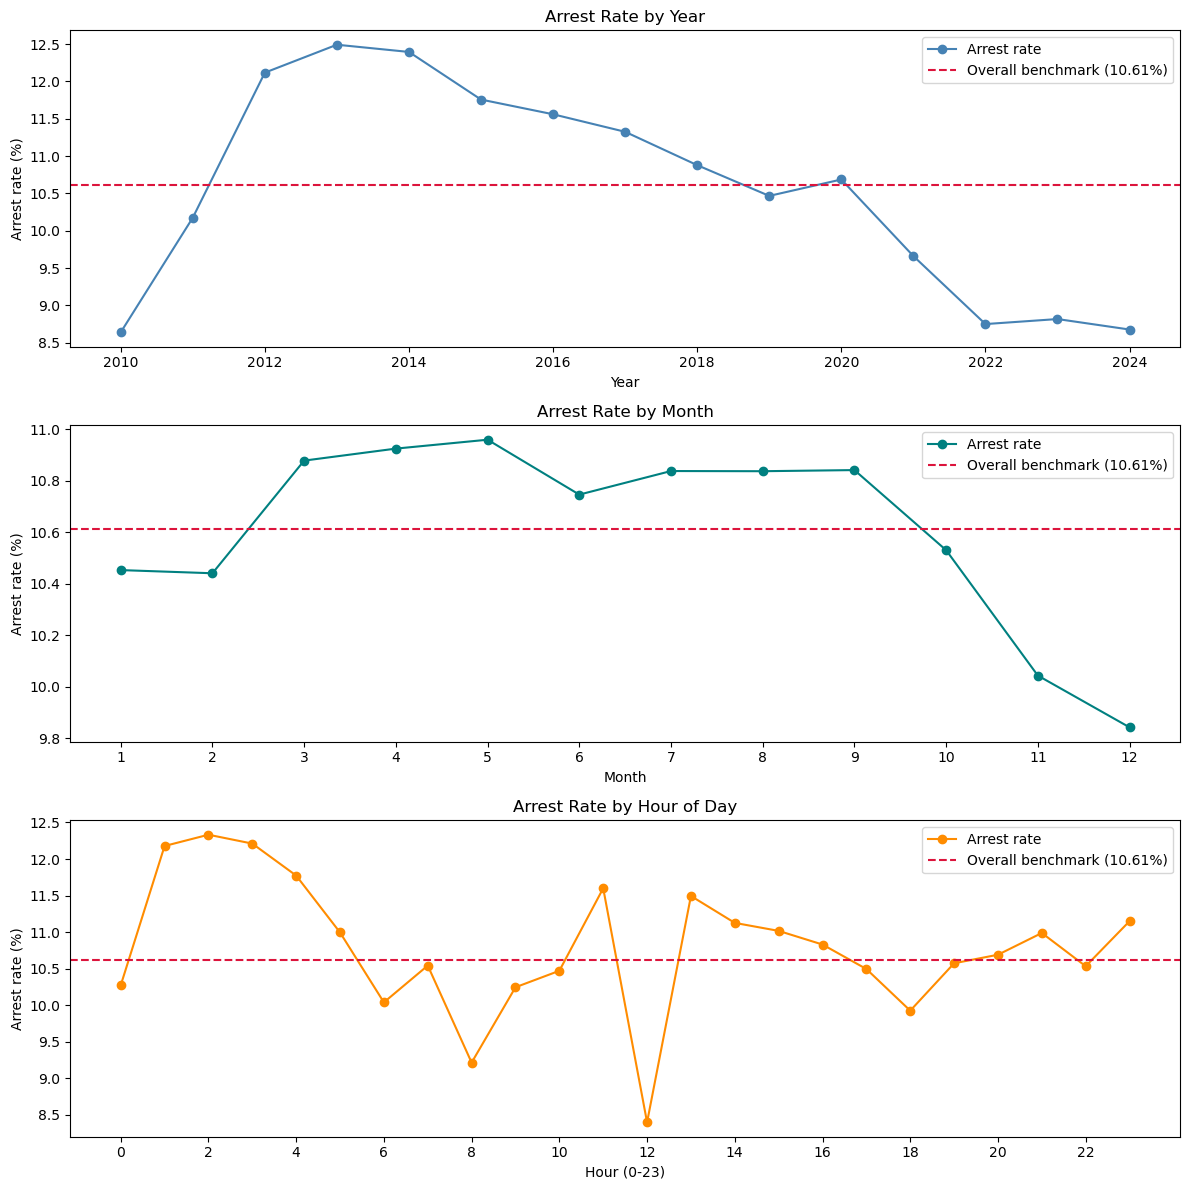

In [21]:
# plot how arrest rates vary by year, month and hour
fig, axes = plt.subplots(3, 1, figsize=(12, 12))
year_rate.plot(ax=axes[0], marker='o', color='steelblue', label='Arrest rate')
month_rate.plot(ax=axes[1], marker='o', color='teal', label='Arrest rate')
hour_rate.plot(ax=axes[2], marker='o', color='darkorange', label='Arrest rate')

for axis in axes:
    axis.axhline(overall_arrest_rate, color='crimson', linestyle='--', linewidth=1.5,
                 label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
    axis.legend()
    axis.set_ylabel('Arrest rate (%)')

axes[0].set_title('Arrest Rate by Year')
axes[0].set_xlabel('Year')
axes[1].set_title('Arrest Rate by Month')
axes[1].set_xlabel('Month')
axes[1].set_xticks(range(1, 13))
axes[2].set_title('Arrest Rate by Hour of Day')
axes[2].set_xlabel('Hour (0-23)')
axes[2].set_xticks(range(0, 24, 2))
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_year_month_hour.png', dpi=300,
            bbox_inches='tight')
plt.show()


Rates change across years, months and hours. This supports trying calendar features. Crime mix, recording and enforcement may also change over time. The 2024 point includes only January and February. I keep later years separate for testing so the model will be checked on a different time period. Approximate or rounded event times may also affect the hourly pattern.

## Weapon, premise, and victim characteristics


In [22]:
# check the weapon code and description for recorded involvement
weapon_desc = df['Weapon Desc'].fillna('').str.upper().str.strip()
weapon_code = df['Weapon Used Cd']
none_labels = {'', 'NONE', 'UNKNOWN', 'UNK'}
weapon_involved = ((weapon_code.notna() & (weapon_code != 0)) |
                   (~weapon_desc.isin(none_labels)))


In [23]:
# compare rates with and without recorded weapon involvement
tmp_weapon = df.copy()
tmp_weapon['weapon_involved'] = np.where(
    weapon_involved, 'Weapon', 'No Weapon')
weapon_vs_none_rate = (tmp_weapon.groupby('weapon_involved')['Arrested']
                       .mean().mul(100)
                       .reindex(['No Weapon', 'Weapon']))


In [24]:
# find arrest rates for the ten most common weapon descriptions
top_weapons = tmp_weapon.loc[
    tmp_weapon['weapon_involved'] == 'Weapon', 'Weapon Desc']
top_weapon_types = top_weapons.value_counts().head(10).index
weapon_subset = tmp_weapon[tmp_weapon['Weapon Desc'].isin(top_weapon_types)]
top_weapon_rates = weapon_subset.groupby('Weapon Desc').agg(
    count=('Arrested', 'size'), arrest_rate=('Arrested', 'mean'))
top_weapon_rates = top_weapon_rates.sort_values(by='count', ascending=False)
top_weapon_rates['arrest_rate_pct'] = top_weapon_rates['arrest_rate'] * 100

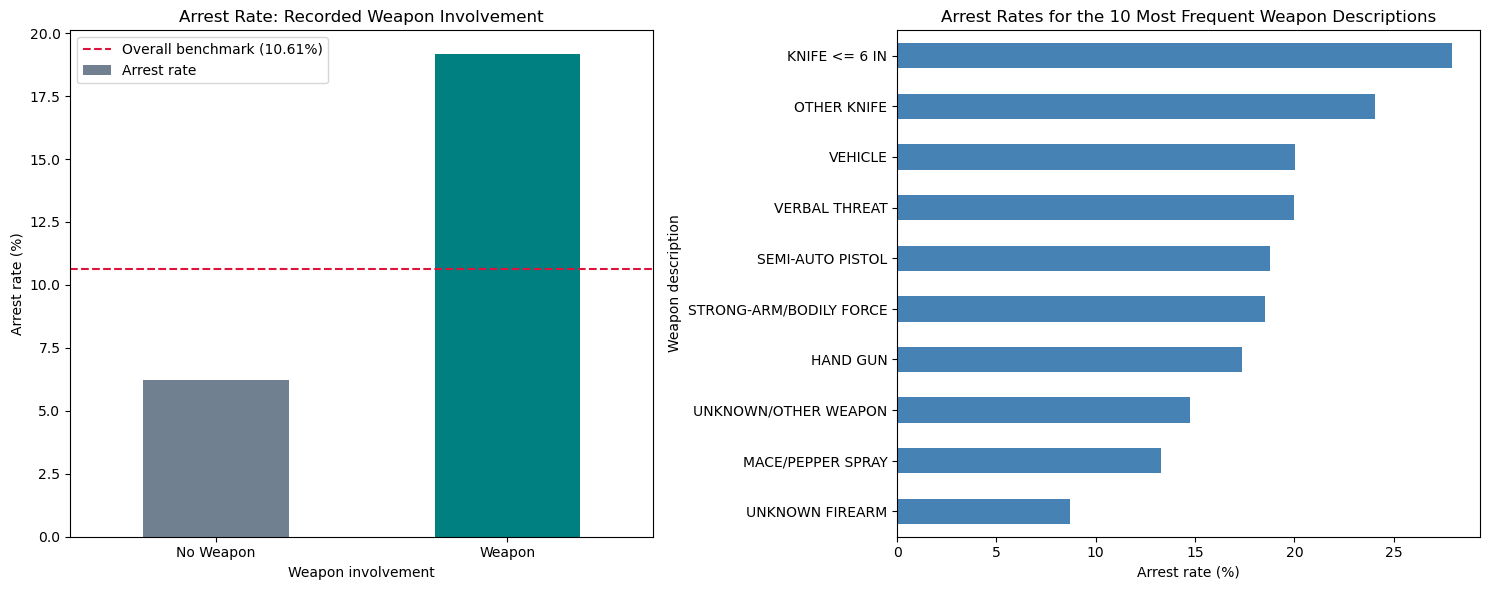

In [25]:
# plot arrest rates by recorded weapon involvement and type
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
weapon_vs_none_rate.plot(kind='bar', ax=ax[0], color=['slategray', 'teal'], rot=0, label='Arrest rate')
ax[0].axhline(overall_arrest_rate, color='crimson', linestyle='--',
              label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
ax[0].legend()
ax[0].set_title('Arrest Rate: Recorded Weapon Involvement')
ax[0].set_xlabel('Weapon involvement')
ax[0].set_ylabel('Arrest rate (%)')
top_weapon_rates['arrest_rate_pct'].sort_values().plot(
    kind='barh', ax=ax[1], color='steelblue')
ax[1].set_title('Arrest Rates for the 10 Most Frequent Weapon Descriptions')
ax[1].set_xlabel('Arrest rate (%)')
ax[1].set_ylabel('Weapon description')
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_weapon.png', dpi=150)
plt.show()

In [26]:
# show counts and arrest rates for common weapon descriptions
top_weapon_rates[['count', 'arrest_rate_pct']].round(2)


,count,arrest_rate_pct
Weapon Desc,,
STRONG-ARM/BODILY FORCE,592228,18.53
UNKNOWN/OTHER WEAPON,90466,14.75
VERBAL THREAT,80663,19.98
HAND GUN,52888,17.34
SEMI-AUTO PISTOL,19707,18.77
KNIFE <= 6 IN,19289,27.94
OTHER KNIFE,15264,24.06
UNKNOWN FIREARM,14091,8.72
VEHICLE,10237,20.01


In [27]:
# print the rates with and without recorded weapon involvement
print(f'No recorded weapon: {weapon_vs_none_rate.loc["No Weapon"]:.2f}%')
print(f'Recorded weapon involvement: {weapon_vs_none_rate.loc["Weapon"]:.2f}%')

No recorded weapon: 6.24%
Recorded weapon involvement: 19.15%


### Approximate confidence interval for the rate difference

I use a 95% normal-approximation interval for each arrest proportion and for the difference between the two proportions. The calculation assumes independent records. Because these are historical records rather than a random sample, the interval is a rough measure of process uncertainty and may be too narrow; it does not adjust for time, crime mix, or location.

In [28]:
weapon_counts = tmp_weapon.groupby('weapon_involved')['Arrested'].agg(
    ['sum', 'count'])
weapon_ci_rows = []

for label in ['No Weapon', 'Weapon']:
    n = weapon_counts.loc[label, 'count']
    arrests = weapon_counts.loc[label, 'sum']
    rate = arrests / n
    margin = 1.96 * np.sqrt(rate * (1 - rate) / n)
    weapon_ci_rows.append({
        'group': label,
        'rows': n,
        'arrests': arrests,
        'rate_pct': rate * 100,
        'lower_95_pct': (rate - margin) * 100,
        'upper_95_pct': (rate + margin) * 100
    })

weapon_ci_df = pd.DataFrame(weapon_ci_rows)
weapon_ci_df.round(2)

,group,rows,arrests,rate_pct,lower_95_pct,upper_95_pct
0,No Weapon,1976102,123237,6.24,6.20,6.27
1,Weapon,1012832,193983,19.15,19.08,19.23


In [29]:
no_weapon_rate = (weapon_counts.loc['No Weapon', 'sum'] /
                  weapon_counts.loc['No Weapon', 'count'])
weapon_rate = (weapon_counts.loc['Weapon', 'sum'] /
               weapon_counts.loc['Weapon', 'count'])
rate_difference = weapon_rate - no_weapon_rate
difference_se = np.sqrt(
    no_weapon_rate * (1 - no_weapon_rate) /
    weapon_counts.loc['No Weapon', 'count'] +
    weapon_rate * (1 - weapon_rate) /
    weapon_counts.loc['Weapon', 'count'])
difference_low = rate_difference - 1.96 * difference_se
difference_high = rate_difference + 1.96 * difference_se
print(f'Rate difference: {rate_difference * 100:.2f} percentage points')
print(f'Approx. 95% CI: {difference_low * 100:.2f} to '
      f'{difference_high * 100:.2f} percentage points')

Rate difference: 12.92 percentage points
Approx. 95% CI: 12.83 to 13.00 percentage points


The approximate 95% interval for the rate difference excludes zero, consistent with an association in these records. Crime mix, time, location and record practices may also differ. The source includes bodily force and other descriptions, not just guns. Missing weapon information does not prove that there was no weapon.

In [30]:
# group common types of places and label the rest as other
premise = (df['Premis Desc']
           .replace({'MULTI-UNIT DWELLING (APARTMENT, DUPLEX, ETC)':
                     'MULTI-UNIT DWELLING'})
           .fillna('Unknown').astype(str).str.strip())
top_premises = premise.value_counts().head(12).index
premise_grouped = np.where(premise.isin(top_premises), premise, 'Other')


In [31]:
# calculate incident counts and arrest rates for each place group
premise_rates = df.assign(premise_group=premise_grouped).groupby('premise_group').agg(
    count=('Arrested', 'size'), arrest_rate=('Arrested', 'mean'))
premise_rates = premise_rates.sort_values(by='count', ascending=False)
premise_rates['arrest_rate_pct'] = premise_rates['arrest_rate'] * 100

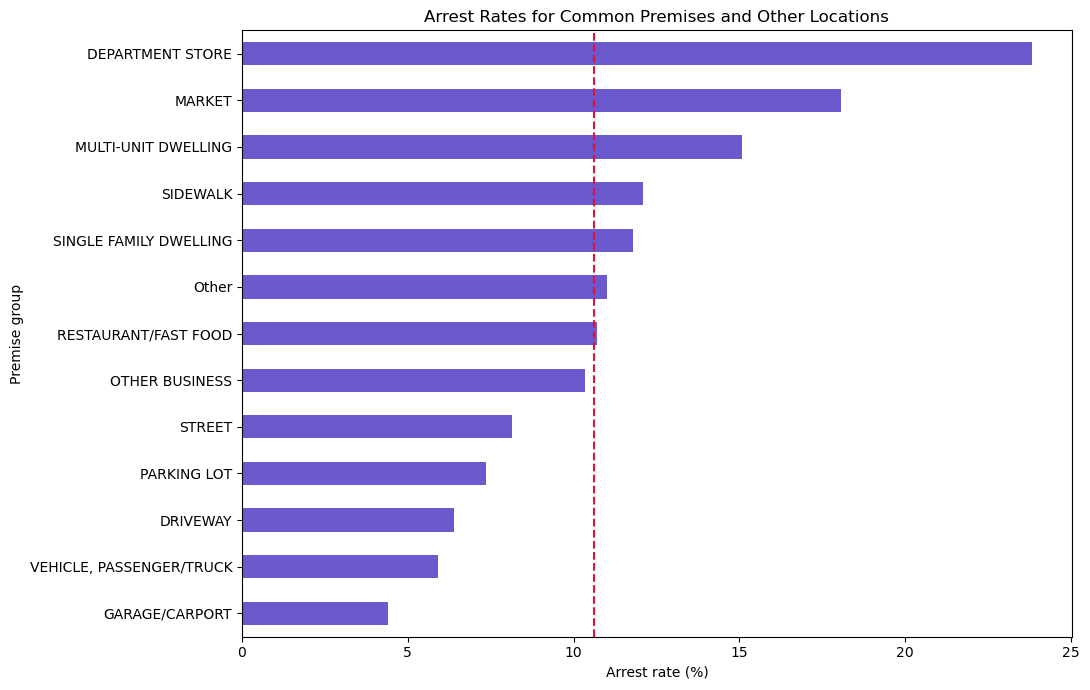

In [32]:
# plot arrest rates for the different types of places
fig, ax = plt.subplots(figsize=(11, 7))
premise_rates['arrest_rate_pct'].sort_values().plot(kind='barh', ax=ax, color='slateblue')
ax.axvline(overall_arrest_rate, color='crimson', linestyle='--')
ax.set_title('Arrest Rates for Common Premises and Other Locations')
ax.set_xlabel('Arrest rate (%)')
ax.set_ylabel('Premise group')
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_premise_top_other.png', dpi=150)
plt.show()

In [33]:
# show place-group counts and rates sorted by arrest rate
premise_rates[['count', 'arrest_rate_pct']].round(2).sort_values(
    by='arrest_rate_pct', ascending=False)


,count,arrest_rate_pct
premise_group,,
DEPARTMENT STORE,39727,23.83
MARKET,28355,18.07
MULTI-UNIT DWELLING,372300,15.09
SIDEWALK,142713,12.10
SINGLE FAMILY DWELLING,576181,11.80
Other,531309,11.00
RESTAURANT/FAST FOOD,40062,10.70
OTHER BUSINESS,138515,10.33
STREET,694636,8.14


Rates also differ by the type of place where a crime occurs. These differences may reflect crime type, witnesses or security staff. Grouping premises keeps the feature easier to use. This EDA chart uses all records, but the feature notebook selects the most common premises from training records only.

In [34]:
# group victim ages and keep missing ages in an unknown group
tmp_demo = df.copy()
age_bins = [0, 18, 25, 35, 45, 55, 65, 120]
age_labels = ['0-17', '18-24', '25-34', '35-44', '45-54', '55-64', '65+']
tmp_demo['age_band'] = pd.cut(
    tmp_demo['Vict Age'], bins=age_bins, labels=age_labels, right=False)
tmp_demo['age_band'] = tmp_demo['age_band'].astype('object').fillna('Unknown')


In [35]:
# calculate arrest rates by victim age, sex and descent
age_rates = tmp_demo.groupby('age_band').agg(
    count=('Arrested', 'size'), rate=('Arrested', 'mean'))
age_rates['rate_pct'] = age_rates['rate'] * 100
age_rates = age_rates.reindex(age_labels + ['Unknown'])
sex_rates = tmp_demo.groupby('Vict Sex').agg(
    count=('Arrested', 'size'), rate=('Arrested', 'mean'))
sex_rates['rate_pct'] = sex_rates['rate'] * 100
sex_rates = sex_rates.sort_values(by='rate_pct', ascending=False)
descent_rates = tmp_demo.groupby('Vict Descent').agg(
    count=('Arrested', 'size'), rate=('Arrested', 'mean'))
descent_rates['rate_pct'] = descent_rates['rate'] * 100
descent_rates = descent_rates.sort_values(by='rate_pct', ascending=False)

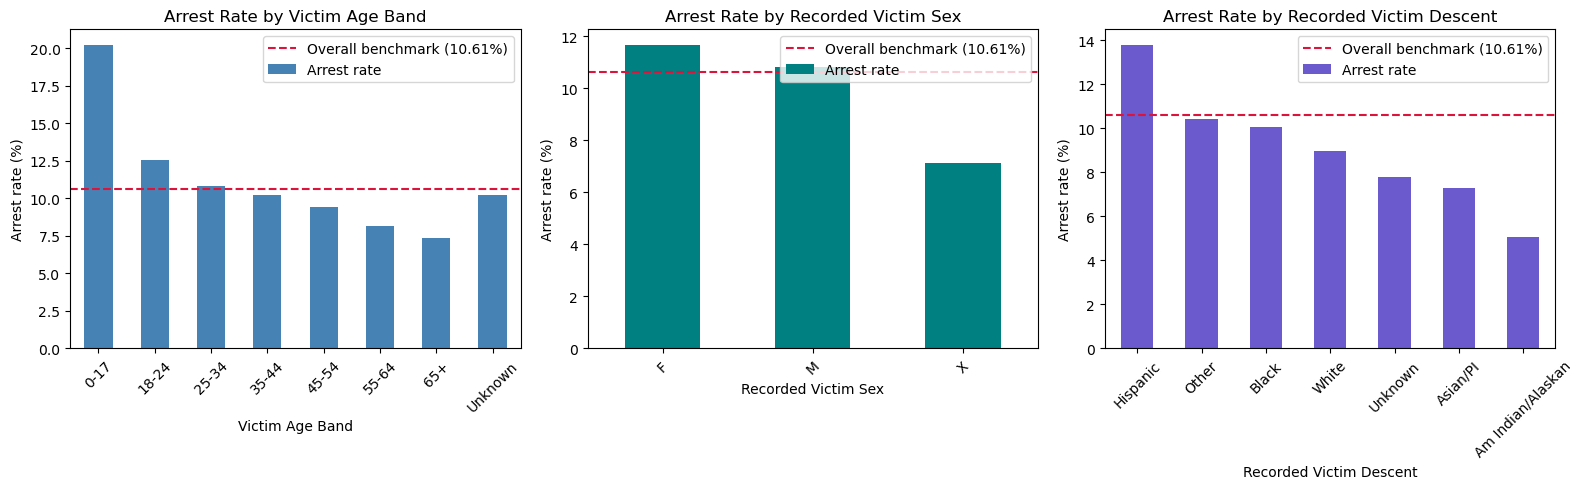

In [36]:
# plot arrest rates for the victim groups
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for rates, axis, label, color in [
    (age_rates, ax[0], 'Victim Age Band', 'steelblue'),
    (sex_rates, ax[1], 'Recorded Victim Sex', 'teal'),
    (descent_rates, ax[2], 'Recorded Victim Descent', 'slateblue')
]:
    rates['rate_pct'].plot(kind='bar', ax=axis, color=color, label='Arrest rate')
    axis.axhline(overall_arrest_rate, color='crimson', linestyle='--',
                 label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
    axis.legend(loc='upper right')
    axis.set_title(f'Arrest Rate by {label}')
    axis.set_xlabel(label)
    axis.set_ylabel('Arrest rate (%)')
    axis.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_victim_demographics.png', dpi=150)
plt.show()

In [37]:
# show incident counts and arrest rates by age group
age_rates[['count', 'rate_pct']].round(2)


,count,rate_pct
age_band,,
0-17,127339,20.25
18-24,340203,12.58
25-34,627573,10.82
35-44,491687,10.24
45-54,388805,9.44
55-64,254171,8.15
65+,164603,7.33
Unknown,594553,10.24


In [38]:
# show incident counts and arrest rates by recorded victim sex
sex_rates[['count', 'rate_pct']].round(2)


,count,rate_pct
Vict Sex,,
F,1206431,11.68
M,1331072,10.83
X,451431,7.12


In [39]:
# show incident counts and arrest rates by recorded victim descent
descent_rates[['count', 'rate_pct']].round(2)


,count,rate_pct
Vict Descent,,
Hispanic,988527,13.80
Other,271251,10.43
Black,457385,10.05
White,688589,8.98
Unknown,481892,7.76
Asian/PI,99468,7.27
Am Indian/Alaskan,1822,5.05


The age and demographic groups have different arrest rates, but these comparisons do not account for differences in crime type. `F` and `M` are the source female/male codes; `X` means unknown. Missing ages stay in an `Unknown` group here. Check the counts beside the rates, especially for smaller groups. These are victim details, not offender details, and they should not be used to draw conclusions about individual behavior.

In [40]:
# calculate rates for single and multiple offenses
multi_rates = (df.groupby('Multiple Offenses')['Arrested']
               .agg(count='size', rate='mean'))
multi_rates['rate_pct'] = multi_rates['rate'] * 100
plot_rates = multi_rates.copy()
plot_rates.index = np.where(
    plot_rates.index, 'Multiple Offenses', 'Single Offense')


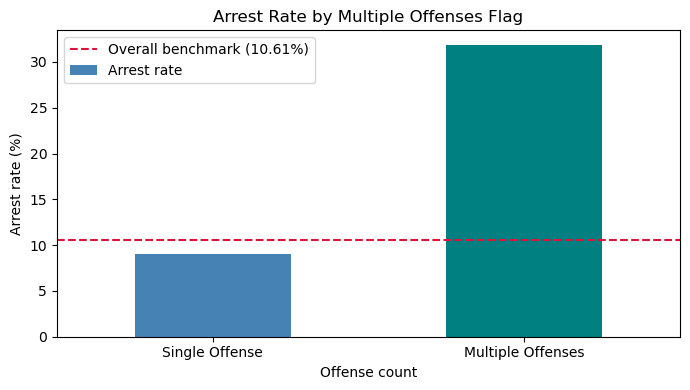

In [41]:
# plot arrest rates for single and multiple offenses
ax = plot_rates['rate_pct'].plot(
    kind='bar', figsize=(7, 4), color=['steelblue', 'teal'], label='Arrest rate')
ax.axhline(overall_arrest_rate, color='crimson', linestyle='--', linewidth=1.5,
           label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
ax.legend()
ax.set_title('Arrest Rate by Multiple Offenses Flag')
ax.set_xlabel('Offense count')
ax.set_ylabel('Arrest rate (%)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_multiple_offenses.png', dpi=300,
            bbox_inches='tight')
plt.show()


In [42]:
# show counts and rates for single and multiple offenses
plot_rates[['count', 'rate_pct']].round(2)


,count,rate_pct
Single Offense,2784304,9.05
Multiple Offenses,204630,31.86


The multiple-offenses flag shows whether one incident lists more than one offense code. It does not mean that the row represents several separate incidents. Exact copies of the same record were removed during cleaning rather than counted as extra offenses.

In [43]:
# calculate the days between occurrence and reporting
tmp_delay = df.copy()
tmp_delay['DATE OCC'] = pd.to_datetime(
    tmp_delay['DATE OCC'], errors='coerce')
tmp_delay['Date Rptd'] = pd.to_datetime(
    tmp_delay['Date Rptd'], errors='coerce')
tmp_delay['report_delay_days'] = (
    tmp_delay['Date Rptd'] - tmp_delay['DATE OCC']).dt.days


In [44]:
# group nonnegative reporting delays into day ranges
delay = tmp_delay.loc[
    tmp_delay['report_delay_days'].notna() &
    (tmp_delay['report_delay_days'] >= 0)].copy()
delay_bins = [-1, 0, 1, 3, 7, 14, 30, 90, 365, 10000]
delay_labels = [
    'Same day', '1 day', '2-3 days', '4-7 days', '8-14 days',
    '15-30 days', '31-90 days', '91-365 days', '365+ days'
]
delay['delay_band'] = pd.cut(
    delay['report_delay_days'], bins=delay_bins, labels=delay_labels)


In [45]:
# calculate incident counts and arrest rates for each delay group
delay_rates = delay.groupby('delay_band')['Arrested'].agg(
    count='size', rate='mean')
delay_rates['rate_pct'] = delay_rates['rate'] * 100
delay_rates = delay_rates.reindex(delay_labels)


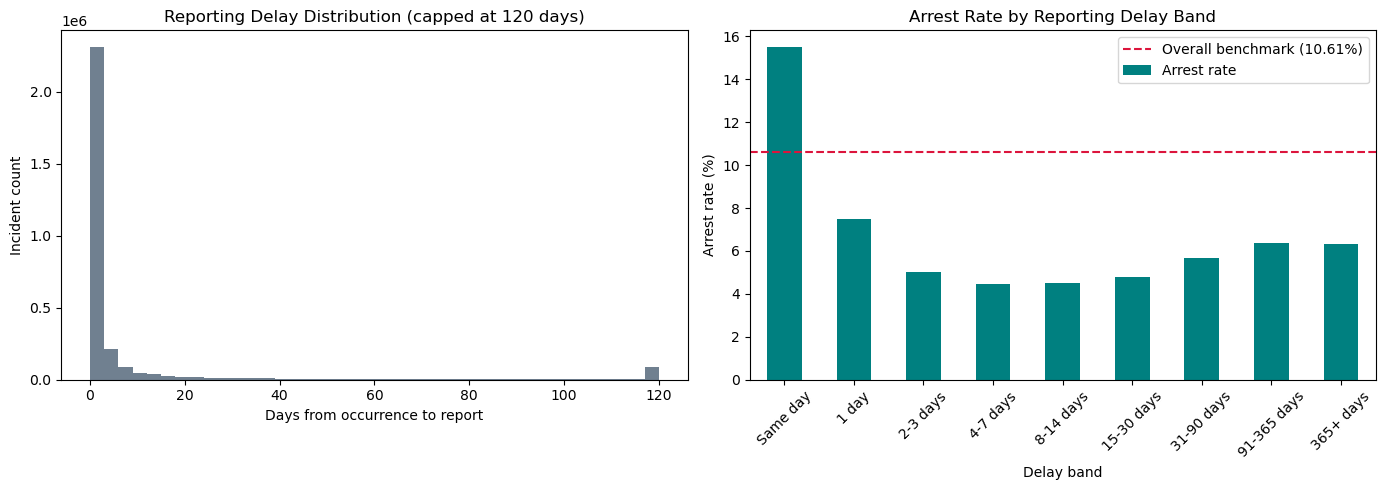

In [46]:
# plot reporting delays and arrest rates by delay group
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
delay['report_delay_days'].clip(upper=120).plot(
    kind='hist', bins=40, ax=axes[0], color='slategray')
axes[0].set_title('Reporting Delay Distribution (capped at 120 days)')
axes[0].set_xlabel('Days from occurrence to report')
axes[0].set_ylabel('Incident count')

delay_rates['rate_pct'].plot(kind='bar', ax=axes[1], color='teal', label='Arrest rate')
axes[1].axhline(overall_arrest_rate, color='crimson', linestyle='--', linewidth=1.5,
                label=f'Overall benchmark ({overall_arrest_rate:.2f}%)')
axes[1].legend()
axes[1].set_title('Arrest Rate by Reporting Delay Band')
axes[1].set_xlabel('Delay band')
axes[1].set_ylabel('Arrest rate (%)')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.savefig('../images/arrest_rate_by_reporting_delay.png', dpi=300,
            bbox_inches='tight')
plt.show()


In [47]:
# show counts and arrest rates for the reporting delay groups
delay_rates[['count', 'rate_pct']].round(2)


,count,rate_pct
delay_band,,
Same day,1423496,15.51
1 day,709089,7.51
2-3 days,280337,5.01
4-7 days,175093,4.48
8-14 days,108384,4.53
15-30 days,93793,4.79
31-90 days,97283,5.65
91-365 days,62700,6.35
365+ days,38759,6.32


## What this suggests for feature engineering

Crime group, police area, premise, weapon group, time, victim details and multiple-offense status are reasonable features to explore. Missing ages need a clear rule, and zero coordinates are not usable Los Angeles locations.

Most reporting delays are short, but some are much longer. The capped histogram makes the plot easier to read; it does not delete those records. Reporting delay is shown for context but is not included in the prepared predictors.

These findings describe the downloaded records, not the final outcome of every case. The next notebook prepares the features using training data to choose the age replacement and category rules. The README summarizes the findings and the model comparison.